# 20 手指手势：从真实RGB照片到21点坐标与逐帧识别

    这是接在19课之后的真实场景实验。你将看到原图、人工标注、自动检测ROI、裁剪与坐标变换、真实预训练CNN内部的卷积/激活/降采样、向量、关键点坐标、误差，以及逐帧视频结果。

    **运行前说明**：沿用项目已有依赖，无需安装MediaPipe包。使用OpenCV Zoo发布的MediaPipe ONNX模型和其Apache-2.0预处理代码；首次联网下载约26MB模型与少量真实样例，以后可离线复用。OpenCV DNN本课使用CPU。Notebook已嵌入实际输出。

    本课**不从头训练关键点大模型**，也不把预测当成人工真值。COCO-WholeBody人工标注用于核对坐标与误差；Google示例照片和TensorFlow.js真实视频用于新输入推理。预训练模型可能见过公开数据，不能把这里的误差称为严格独立测试集成绩。

In [1]:
from pathlib import Path
import sys, json, csv
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
import cv2, numpy as np, matplotlib.pyplot as plt
from course_utils import setup, save_figure
from keypoint_utils import (prepare_keypoints, models, trace_network, plot_channels,
    draw_points, HAND_EDGES, BODY_EDGES, COCO_TO_MP, joint_angle, finger_state,
    export_inventory, infer_video)
setup()
DATA = prepare_keypoints()
PREFIX = '20_hand'
detector, estimator = models('hand')
annotations = json.loads((DATA/'test_coco_wholebody.json').read_text())
print('OpenCV版本', cv2.__version__, '预训练网络固定权重；实际推理CPU')
print('人工标注照片', len(annotations['images']), '人物标注', len(annotations['annotations']))

OpenCV版本 4.12.0 预训练网络固定权重；实际推理CPU
人工标注照片 4 人物标注 14


## 1. 标注文件到底记录什么

    图像左上角是原点，x向右，y向下。像素坐标与归一化坐标不能混用：u=x/W，v=y/H。框采用左上角加宽高xywh；画框前转换为xyxy。

    COCO-WholeBody的身体是17点，每只手21点，点数组按x,y,v排列。v=0未标注，v=1已标注但遮挡，v=2可见；未标注点不能参与监督误差。这里保存原始JSON和可检索的坐标CSV，不把坐标写死在图片里。

原始JSON示例 {"id": 531914, "image_id": 197388, "righthand_valid": true, "righthand_box": [557.05, 149.73, 19.879999999999995, 21.76000000000002]}
前5个人工标注点，列为x,y,v
[[5.6500000e+02 1.5300000e+02 8.7733410e-02]
 [5.6800000e+02 1.5600000e+02 4.6024844e-02]
 [5.7100000e+02 1.5900000e+02 4.6024844e-02]
 [5.7300000e+02 1.6100000e+02 6.9720611e-02]
 [5.7500000e+02 1.6400000e+02 6.2978134e-02]]


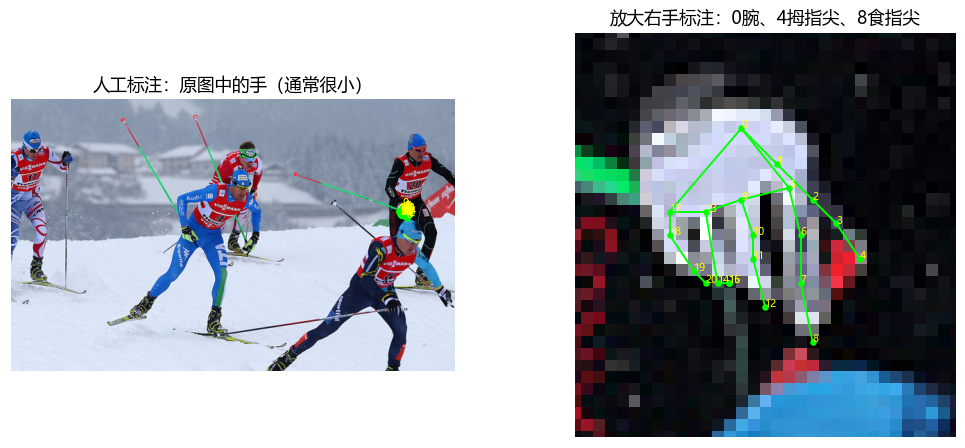

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/20_hand_annotation.png')

In [2]:
ann = next(a for a in annotations['annotations'] if a['id'] == 531914)
gt = np.array(ann['righthand_kpts'], np.float32).reshape(21, 3)
gt_image = cv2.imread(str(DATA/(str(ann['image_id']).zfill(12)+'.jpg')))
mask = gt[:, 2] > 0
print('原始JSON示例', json.dumps({k:ann[k] for k in ['id','image_id','righthand_valid','righthand_box']}, ensure_ascii=False))
print('前5个人工标注点，列为x,y,v', gt[:5], sep='\n')
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
draw_points(axes[0], gt_image, gt, HAND_EDGES, '人工标注：原图中的手（通常很小）', visible=mask)
draw_points(axes[1], gt_image, gt, HAND_EDGES, '放大右手标注：0腕、4拇指尖、8食指尖', visible=mask)
lo, hi = gt[mask,:2].min(0)-8, gt[mask,:2].max(0)+8
axes[1].set_xlim(lo[0], hi[0]); axes[1].set_ylim(hi[1], lo[1])
save_figure(PREFIX+'_annotation')

手的编号不是“第几个发现的亮点”：0是腕，1–4拇指，5–8食指，9–12中指，13–16无名指，17–20小指。人工标注时顺序必须固定。人手绘制点后得到的JSON才是监督答案，模型跑出来的21点是预测。

        本例手只有几十像素，不能期待模型在放大后凭空恢复细节。稍后会用这个困难样本演示低置信度与误差，正常推理使用另一张清晰真实照片。

In [3]:
with (ROOT/'outputs'/(PREFIX+'_ground_truth.csv')).open('w', newline='', encoding='utf-8-sig') as out:
    writer = csv.writer(out); writer.writerow(['keypoint_id','x_pixel','y_pixel','visibility','x_over_width','y_over_height'])
    for i,(x,y,v) in enumerate(gt):
        writer.writerow([i,float(x),float(y),int(v),float(x/gt_image.shape[1]),float(y/gt_image.shape[0])])
print('人工标注坐标已导出，不包含预测值')

人工标注坐标已导出，不包含预测值


## 2. 新图输入：先检测ROI，再缩放进入关键点网络

    原图是H×W×3的BGR。检测器先找手掌/人体，关键点网络再处理其ROI。检测框不是类别概率“变出来”的，检测器有自己的位置输出头与后处理。

    ROI会裁剪、补黑边和旋转；输入关键点网络前转RGB、除255。ONNX接口是NHWC，进入卷积后变成NCHW。尺寸缩小是采样和特征计算，不等同于“逐渐模糊”；有的通道专门强化边缘或局部结构。

原图BGR (376, 358, 3) ROI原图坐标 [ 98.6 169.2 212.6 283.2]
模型输入NHWC (1, 224, 224, 3) 数值范围 0.0 0.8627451062202454


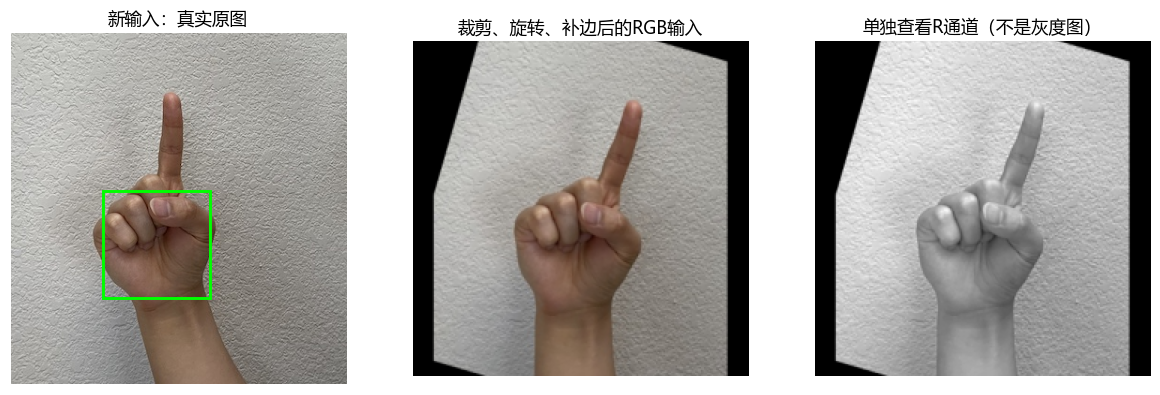

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/20_hand_input_roi.png')

In [4]:
new_image = cv2.imread(str(DATA/'pointing_up.jpg'))
rois = detector.infer(new_image)
if not len(rois): raise RuntimeError('未检测到ROI，请使用一张清晰且完整的图')
roi = rois[0]
result = estimator.infer(new_image, roi)
if result is None: raise RuntimeError('关键点置信度低于阈值，不应强行补造坐标')
preprocessed = estimator._preprocess(new_image, roi)
blob = preprocessed[0]
print('原图BGR', new_image.shape, 'ROI原图坐标', np.round(roi[:4],1))
print('模型输入NHWC', blob.shape, '数值范围', float(blob.min()), float(blob.max()))
fig, axes = plt.subplots(1,3,figsize=(14,5))
axes[0].imshow(cv2.cvtColor(new_image,cv2.COLOR_BGR2RGB)); axes[0].set_title('新输入：真实原图')
x0,y0,x1,y1=roi[:4]
axes[0].add_patch(plt.Rectangle((x0,y0),x1-x0,y1-y0,fill=False,color='lime',lw=2))
axes[1].imshow(blob[0]); axes[1].set_title('裁剪、旋转、补边后的RGB输入')
axes[2].imshow(blob[0,:,:,0],cmap='gray');axes[2].set_title('单独查看R通道（不是灰度图）')
for ax in axes:ax.axis('off')
save_figure(PREFIX+'_input_roi')

## 3. 打开网络：所有算子与真实张量形状

    关闭OpenCV的算子融合，以免卷积与激活合并后看不见中间值。下面取的是同一输入实际前向计算的各层输出，不是对原图重复做模糊滤波。

    全部算子名、权重尺寸和输出尺寸写入CSV。为了能阅读，图中展示早期全部24通道，以及后续尺度的前24通道；每张图明确标注实际总通道数，未展示的数值仍可在outputs列表中索引。不同层使用各自的色阶，同一层通道共用色阶。

In [5]:
names, activations, inventory = trace_network(estimator.model, blob)
export_inventory(inventory, ROOT/'outputs'/(PREFIX+'_operators.csv'))
convs=[i for i,row in enumerate(inventory) if row['type']=='Convolution']
first=convs[0]
pools=[i for i,row in enumerate(inventory) if row['type']=='Pooling']
for row in inventory:
    print(row['index'], row['type'], tuple(row['shape']), '权重', row['weights'])
print('完整算子名称见', PREFIX+'_operators.csv')

0 Permute (1, 3, 224, 224) 权重 []
1 Convolution (1, 24, 112, 112) 权重 [[24, 3, 3, 3], [24, 1]]
2 ReLU6 (1, 24, 112, 112) 权重 []
3 Convolution (1, 24, 112, 112) 权重 [[24, 1, 3, 3], [24, 1]]
4 ReLU6 (1, 24, 112, 112) 权重 []
5 Convolution (1, 16, 112, 112) 权重 [[16, 24, 1, 1], [16, 1]]
6 Convolution (1, 64, 112, 112) 权重 [[64, 16, 1, 1], [64, 1]]
7 ReLU6 (1, 64, 112, 112) 权重 []
8 Convolution (1, 64, 56, 56) 权重 [[64, 1, 3, 3], [64, 1]]
9 ReLU6 (1, 64, 56, 56) 权重 []
10 Convolution (1, 16, 56, 56) 权重 [[16, 64, 1, 1], [16, 1]]
11 Pooling (1, 16, 56, 56) 权重 []
12 NaryEltwise (1, 16, 56, 56) 权重 []
13 Convolution (1, 96, 56, 56) 权重 [[96, 16, 1, 1], [96, 1]]
14 ReLU6 (1, 96, 56, 56) 权重 []
15 Convolution (1, 96, 56, 56) 权重 [[96, 1, 3, 3], [96, 1]]
16 ReLU6 (1, 96, 56, 56) 权重 []
17 Convolution (1, 16, 56, 56) 权重 [[16, 96, 1, 1], [16, 1]]
18 NaryEltwise (1, 16, 56, 56) 权重 []
19 Convolution (1, 96, 56, 56) 权重 [[96, 16, 1, 1], [96, 1]]
20 ReLU6 (1, 96, 56, 56) 权重 []
21 Convolution (1, 96, 28, 28) 权重 [[96, 1,

## 4. 第一层卷积核：3个颜色通道如何合成1个特征通道

    第一层有24个3×3×3卷积核，权重形状为24×3×3×3。每个输出通道对R、G、B三个3×3小块分别乘加，再把3个结果和偏置相加。卷积不是把图“变成一个核”：**核是训练得到的参数，特征图才是图像经过核的输出**。

    模型中的BatchNorm已经折叠进卷积权重与偏置；本课展示的是ONNX实际部署权重。下面手算某一个输出像素，并与网络输出作数值校验。

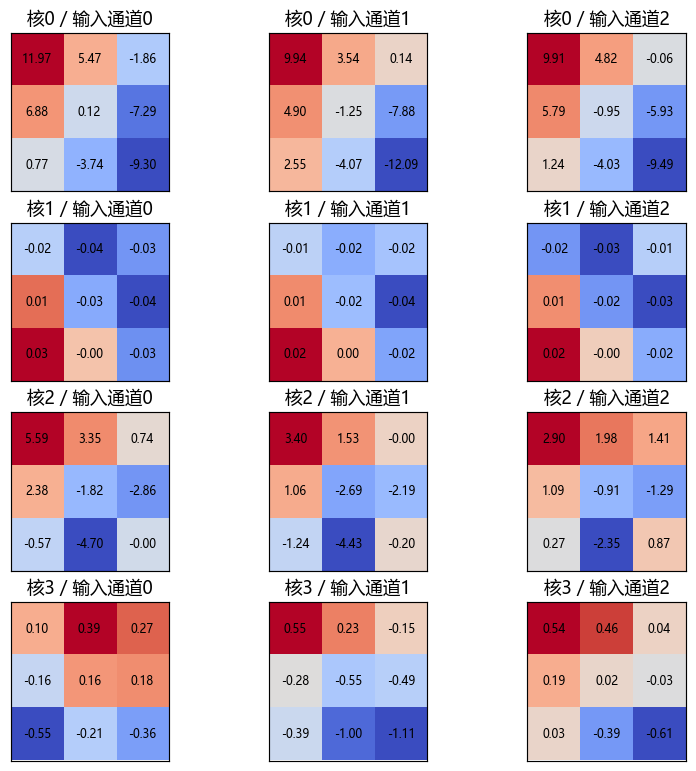

每个颜色通道贡献 [0. 0. 0.] 偏置 0.880859375
实际输入索引起点 (19, 19) 手算 0.880859375 网络 0.880859375 误差 0.0


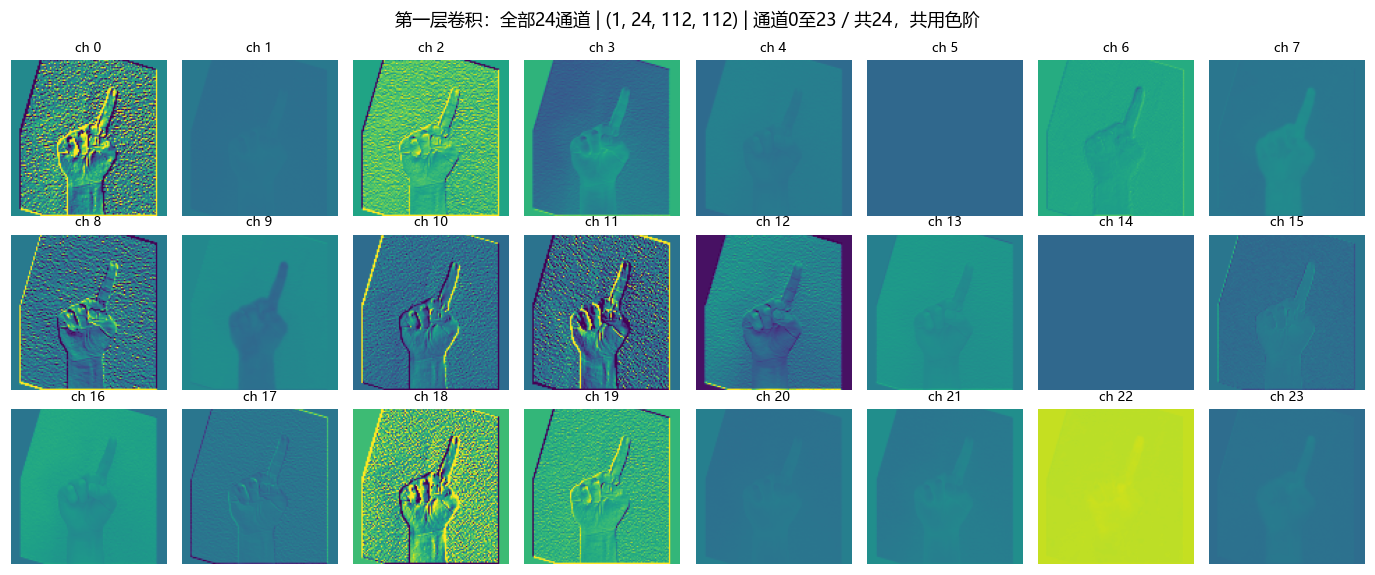

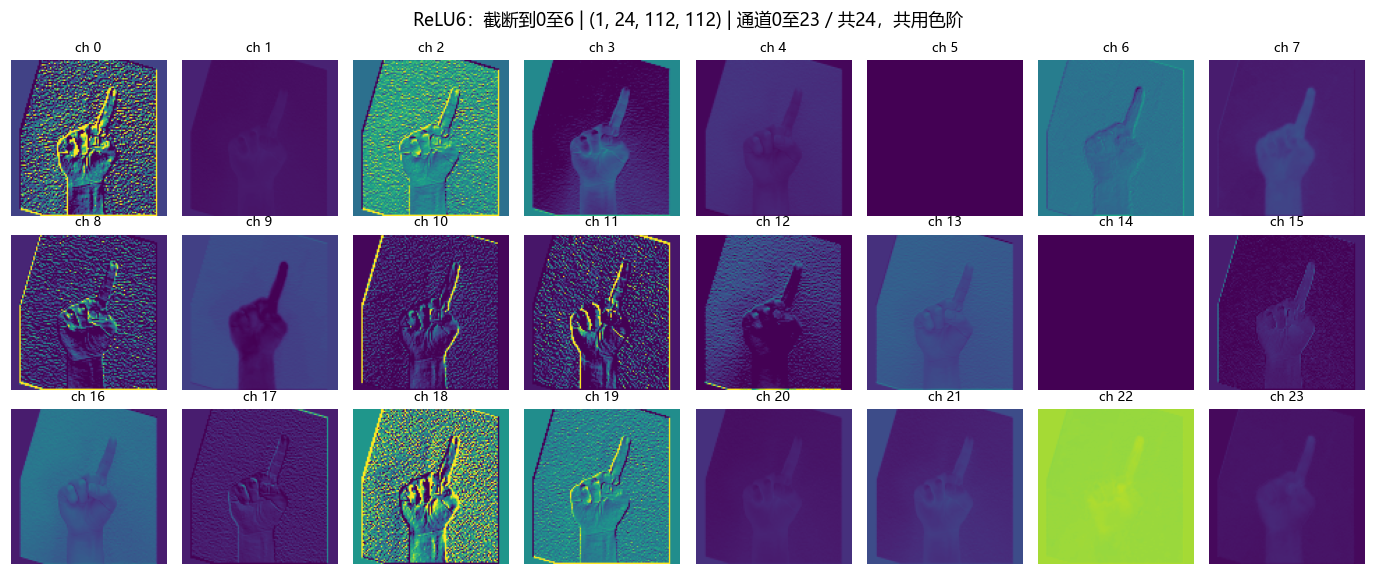

In [6]:
layer = estimator.model.getLayer(estimator.model.getLayerId(names[first]))
weights,bias = layer.blobs
fig,axes=plt.subplots(4,3,figsize=(9,9))
for k in range(4):
    for c in range(3):
        ax=axes[k,c];ax.imshow(weights[k,c],cmap='coolwarm')
        ax.set_title(f'核{k} / 输入通道{c}')
        for y in range(3):
            for x in range(3):ax.text(x,y,f'{weights[k,c,y,x]:.2f}',ha='center',va='center',fontsize=8)
        ax.set_xticks([]);ax.set_yticks([])
save_figure(PREFIX+'_kernels')
# 使用真实卷积前一层的NCHW张量；stride=2。比对两种常见边界补齐偏移。
conv_input=activations[first-1][0]
y,x=10,10
checks=[]
for offset in [-1,0]:
    patch=conv_input[:,2*y+offset:2*y+offset+3,2*x+offset:2*x+offset+3]
    terms=(patch*weights[0]).sum(axis=(1,2))
    manual=terms.sum()+bias.reshape(-1)[0]
    checks.append((abs(float(manual-activations[first][0,0,y,x])),offset,terms,manual))
error,offset,terms,manual=min(checks,key=lambda t:t[0])
assert error<1e-4
print('每个颜色通道贡献',terms,'偏置',float(bias.reshape(-1)[0]))
print('实际输入索引起点', (2*y+offset,2*x+offset), '手算',float(manual),'网络',float(activations[first][0,0,y,x]),'误差',error)
plot_channels(activations[first], '第一层卷积：全部24通道', PREFIX+'_conv1')
plot_channels(activations[first+1], 'ReLU6：截断到0至6', PREFIX+'_relu1')

## 5. 深度卷积、1×1卷积与降采样

    深度卷积的权重是C×1×K×K：每个通道各自用一个小核；1×1卷积则在同一空间位置混合多个通道，改变通道数。MobileNet风格网络常把这两步分开以减少计算量。

    ReLU6把负数置0、大于6的值截为6；它是非线性，不改变张量形状。最大池化选局部最大值；步长2卷积也能缩小空间尺寸，但同时学习权重。不能把所有尺寸下降都叫池化。

首个深度卷积权重 [24, 1, 3, 3] 输出 [1, 24, 112, 112]


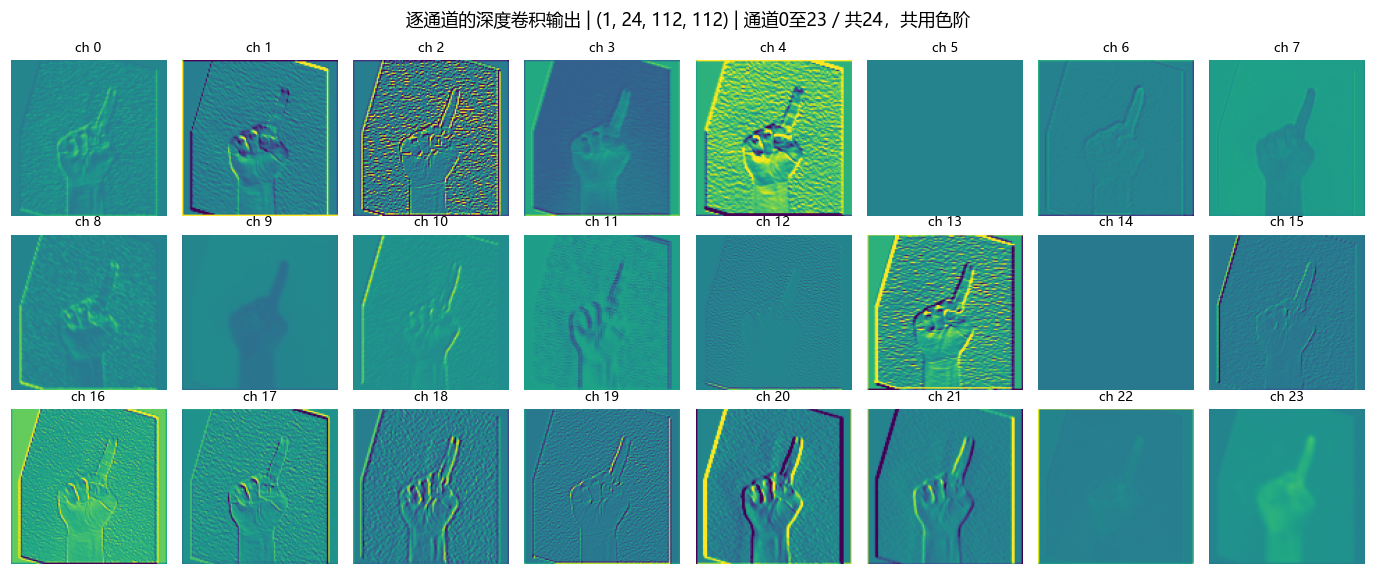

第一处池化 11 [1, 16, 56, 56]


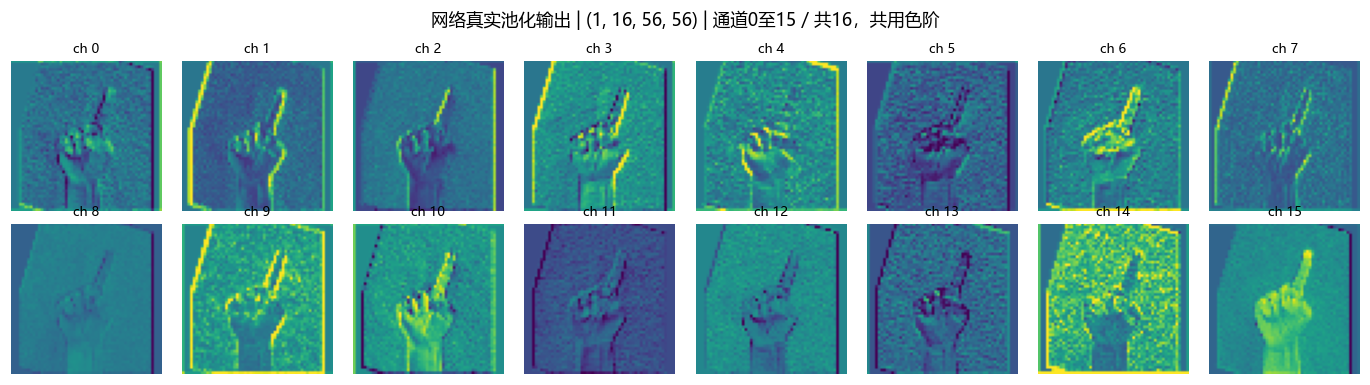

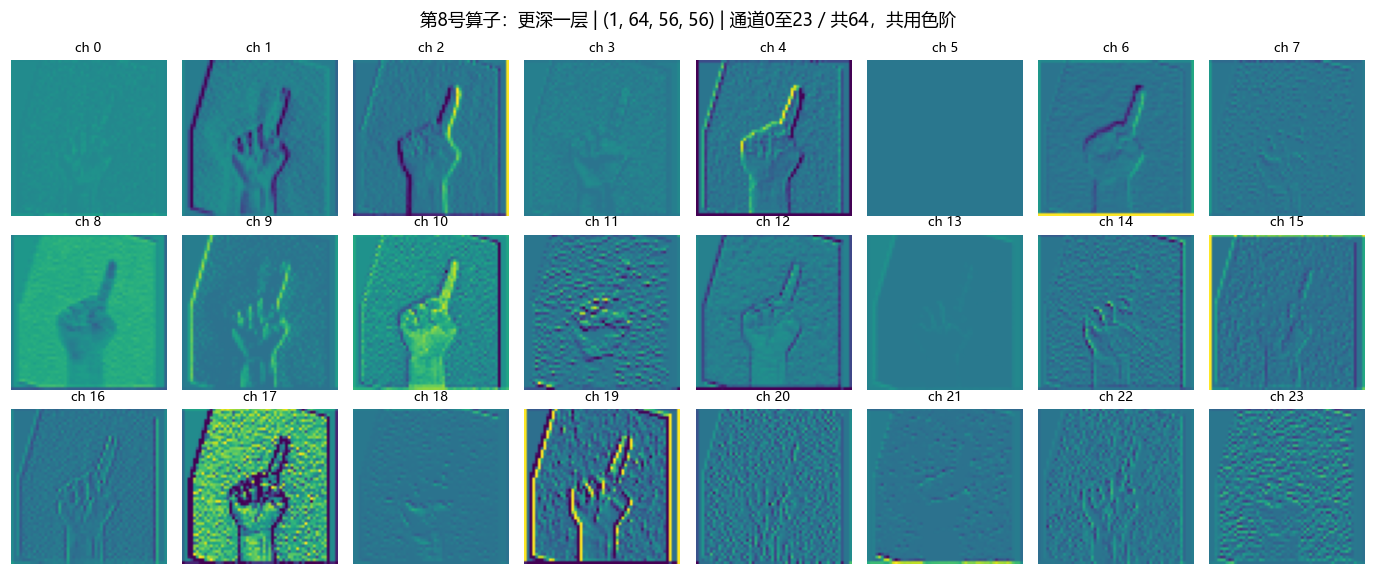

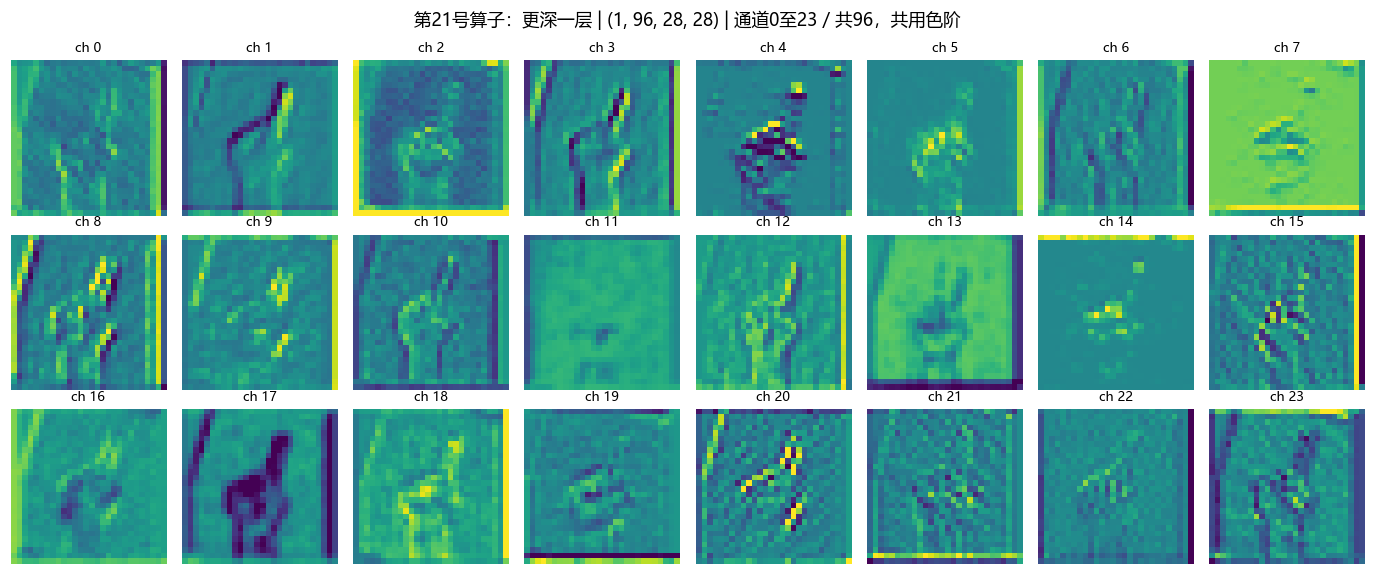

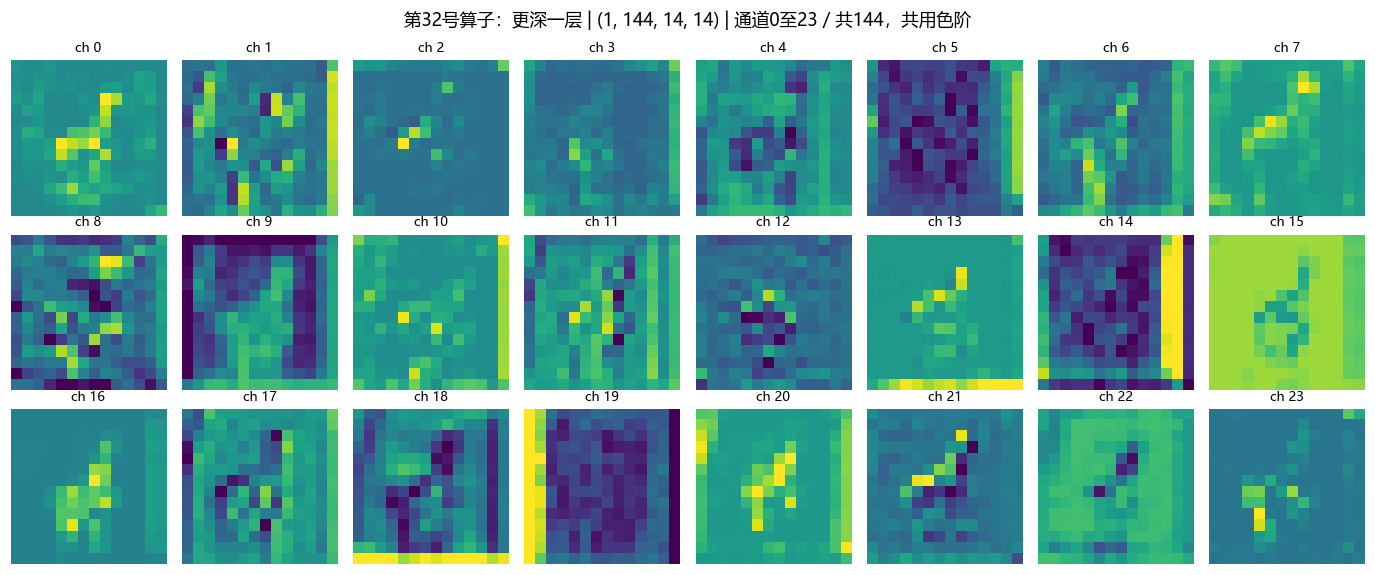

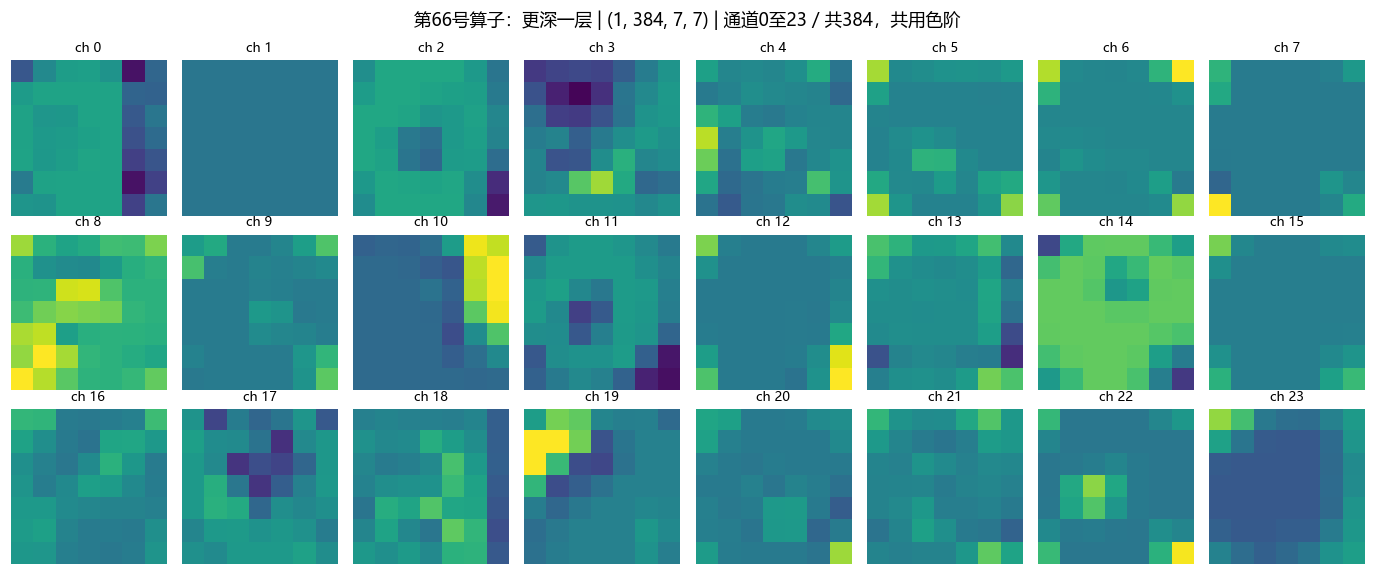

In [7]:
depth=next(i for i in convs if len(inventory[i]['weights'][0])==4 and inventory[i]['weights'][0][1]==1)
print('首个深度卷积权重', inventory[depth]['weights'][0], '输出', inventory[depth]['shape'])
plot_channels(activations[depth], '逐通道的深度卷积输出', PREFIX+'_depthwise')
if pools:
    pool=pools[0]
    print('第一处池化',pool,inventory[pool]['shape'])
    plot_channels(activations[pool], '网络真实池化输出', PREFIX+'_pool')
# 主干按空间尺度挑选第一次出现的卷积，保留真实通道数。
selected=[]; seen=set()
for i in convs:
    a=activations[i]
    if a.ndim==4 and a.shape[-1] in [56,28,14,7,32,16,8,4,2] and a.shape[-1] not in seen:
        selected.append(i);seen.add(a.shape[-1])
selected=selected[:4]
for i in selected:
    plot_channels(activations[i], f'第{i}号算子：更深一层', PREFIX+f'_stage_{i}')

## 6. 从空间特征到向量，再到坐标

    这里看实际网络的计算路径。手部模型通过全局平均池化把每个通道压成一个值，再通过全连接层输出21×3坐标。人体模型用192×2×2特征，最后一个覆盖2×2空间的卷积与“展平向量×权重”数值等价，输出39×5坐标/置信度参数。人体网络还另有热图、分割和世界坐标分支，不能把这些分支误认为一条串行管线。

In [8]:
vector_index=next(i for i,r in enumerate(inventory) if r['type']=='Reshape' and r['shape']==[1,672])
vector=activations[vector_index][0]
head=next(i for i,r in enumerate(inventory) if r['type']=='Gemm' and r['weights'][0]==[672,63])
w,b=estimator.model.getLayer(estimator.model.getLayerId(names[head])).blobs
manual=vector@w+b.reshape(-1)
raw=activations[names.index('Identity')][0]
np.testing.assert_allclose(manual,raw,atol=2e-3,rtol=2e-4)
print('672维向量 → 672×63权重 → 63个数 → 21×3')
print('手算输出与网络最大误差',float(np.max(abs(manual-raw))))
points=result[4:67].reshape(21,3)

672维向量 → 672×63权重 → 63个数 → 21×3
手算输出与网络最大误差 4.57763671875e-05


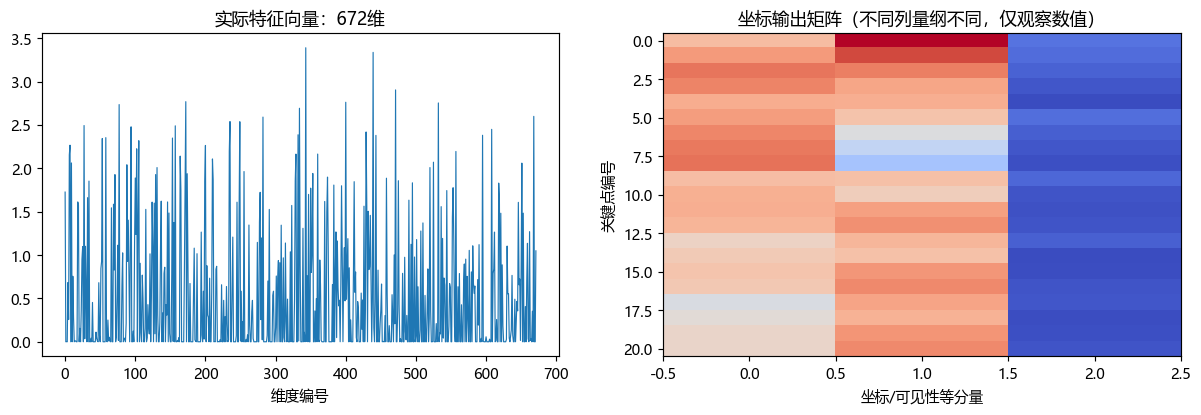

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/20_hand_vector_output.png')

In [9]:
fig,axes=plt.subplots(1,2,figsize=(14,4))
axes[0].plot(vector,lw=.8);axes[0].set_title(f'实际特征向量：{len(vector)}维');axes[0].set_xlabel('维度编号')
axes[1].imshow(raw.reshape(-1,3) if len(raw)==63 else raw.reshape(-1,5),aspect='auto',cmap='coolwarm')
axes[1].set_title('坐标输出矩阵（不同列量纲不同，仅观察数值）');axes[1].set_xlabel('坐标/可见性等分量');axes[1].set_ylabel('关键点编号')
save_figure(PREFIX+'_vector_output')

## 7. 模型坐标如何回到原图

    模型输出坐标属于旋转补边后的输入平面。必须先减去输入中心，乘ROI/输入尺寸比例，再逆旋转，最后加回ROI中心和裁剪偏移；直接乘原图宽高会错位。预处理返回的旋转矩阵和pad_bias就是为逆变换保留的。

    下面并列打印输入坐标、还原后的原图坐标与归一化坐标；画出的编号仍是模型自己的编号。x/W和y/H便于跨分辨率保存，z是模型的相对深度，不能把二维图像中的z直接当成实测距离。

预处理旋转角度（度） -16.20795960233204 补边/裁剪偏移 [-80 -71]
输入坐标前5行
[[108.95454 177.915  ]
 [128.74252 161.29395]
 [144.52972 140.35977]
 [138.40234 122.63455]
 [118.77254 117.65278]]
逆变换回原图前5行
[[170.94857788 282.64718628]
 [192.87652588 249.84608459]
 [207.10081482 212.42649841]
 [190.56361389 189.05075073]
 [159.66123962 190.11247253]]
归一化前5行
[[0.47750999 0.75172124]
 [0.53876125 0.66448427]
 [0.5784939  0.56496409]
 [0.5323006  0.50279455]
 [0.44598112 0.50561828]]


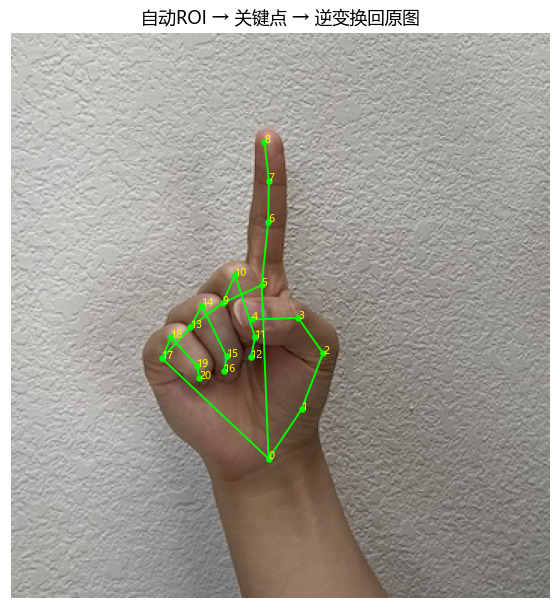

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/20_hand_prediction.png')

In [10]:
print('预处理旋转角度（度）',float(preprocessed[2]),'补边/裁剪偏移',preprocessed[4])
print('输入坐标前5行',raw.reshape(-1,3)[:5,:2],sep='\n')
print('逆变换回原图前5行',points[:5,:2],sep='\n')
norm=points[:,:2]/[new_image.shape[1],new_image.shape[0]]
print('归一化前5行',norm[:5],sep='\n')
fig,ax=plt.subplots(figsize=(8,7))
draw_points(ax,new_image,points,HAND_EDGES,'自动ROI → 关键点 → 逆变换回原图')
save_figure(PREFIX+'_prediction')

## 8. 损失：一定要和人工答案比较

    关键点回归可用可见点上的L1、L2或SmoothL1监督。这里计算归一化二维MSE和平均像素误差，用于理解监督目标。预训练模型没有在本课更新参数；这些数值不是原论文完整训练损失，也不包含没有标注的三维、分割、检测损失。

    v=0的点必须屏蔽，低置信度预测也必须报告。正确做法是先检查检测是否成功，再谈点误差，而不是忽略失败样本只报好看的分数。

In [11]:
# 为了单独检查坐标回归，用人工点构建oracle掌部ROI；这不是完整检测性能。
palm_points=gt[[0,5,9,13,17,1,2],:2]
oracle_roi=np.r_[palm_points.min(0),palm_points.max(0),palm_points.ravel(),1.]
saved_threshold=estimator.conf_threshold
try:
    estimator.conf_threshold=0.0  # 只为观察失败原因，正常推理仍用0.5
    difficult=estimator.infer(gt_image,oracle_roi)
finally:
    estimator.conf_threshold=saved_threshold
pred=difficult[4:67].reshape(21,3)
gt_confidence=float(difficult[-1])
print('困难小手置信度',gt_confidence,'正常阈值应拒绝',gt_confidence<saved_threshold)
figure_edges=HAND_EDGES

困难小手置信度 0.09633442014455795 正常阈值应拒绝 True


参与监督的点 21 归一化二维MSE 2.081759666647764e-05 平均像素误差 2.4182031252880694


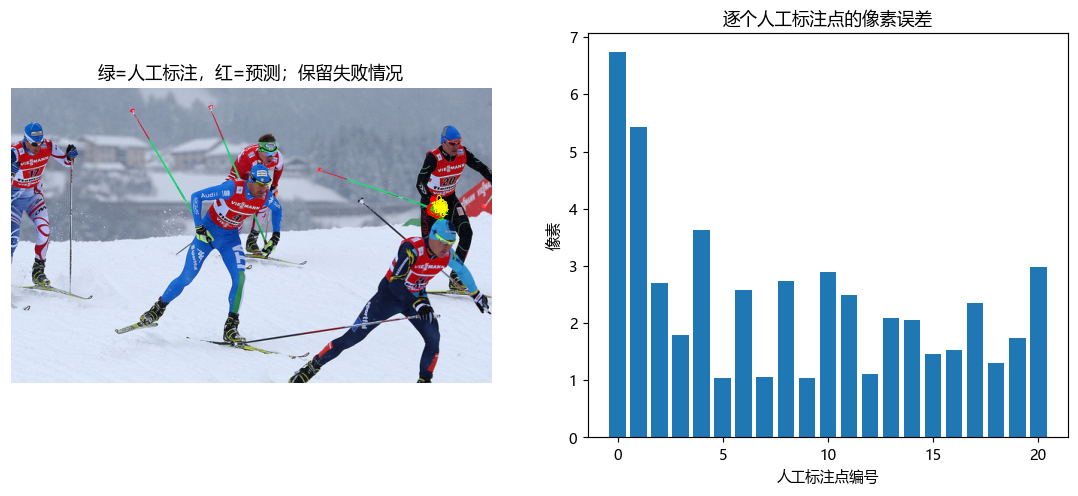

280

In [12]:
delta=pred[mask,:2]-gt[mask,:2]
squared=(delta/[gt_image.shape[1],gt_image.shape[0]])**2
mse=float(squared.mean());pixel_error=np.linalg.norm(delta,axis=1)
print('参与监督的点',int(mask.sum()),'归一化二维MSE',mse,'平均像素误差',float(pixel_error.mean()))
fig,axes=plt.subplots(1,2,figsize=(13,5))
draw_points(axes[0],gt_image,gt,figure_edges,'绿=人工标注，红=预测；保留失败情况',visible=mask)
axes[0].scatter(pred[mask,0],pred[mask,1],s=15,c='red')
for a,b in zip(gt[mask,:2],pred[mask,:2]):axes[0].plot([a[0],b[0]],[a[1],b[1]],'r-',lw=.6)
axes[1].bar(np.where(mask)[0],pixel_error);axes[1].set_title('逐个人工标注点的像素误差');axes[1].set_xlabel('人工标注点编号');axes[1].set_ylabel('像素')
save_figure(PREFIX+'_loss')
(ROOT/'outputs'/(PREFIX+'_metrics.json')).write_text(json.dumps({'reference_image_id':ann['image_id'],'annotation_id':ann['id'],
    'visible_points':int(mask.sum()),'normalized_2d_mse':mse,'mean_pixel_error':float(pixel_error.mean()),
    'confidence':gt_confidence,'evaluation':'small reference example, not independent benchmark'},indent=2),encoding='utf-8')

## 9. 21点怎样变成“伸食指”等手势

        关键点网络输出的是坐标，不会自动输出业务需要的手势名称。本课把坐标减去腕点，再按腕到中指根的距离归一化，得到42维二维特征；也可计算5根手指关节角度，得到5维可解释特征。

        为便于逐项理解，这里用155°阈值判断手指伸直，并用显式规则输出thumb_up、pointing_up、open_palm等；它不是训练出的通用手语分类器，也没有分类概率或可反向传播的分类交叉熵。19课已经演示了真正的分类logits/softmax/交叉熵。工程上可用多人多光照采集的手势标签训练MLP、SVM或时序模型，按人物/录像分组划分集合。

pointing_up.jpg 特征 (42,) 角度 [ 94.4 171.5  34.7  46.9  57.3] 伸直 [0 1 0 0 0] 规则输出 pointing_up
thumb_up.jpg 特征 (42,) 角度 [178.1  11.7   4.6   2.7   6.1] 伸直 [1 0 0 0 0] 规则输出 thumb_up
woman_hands.jpg 特征 (42,) 角度 [135.4 166.4 168.8 178.2 163.2] 伸直 [0 1 1 1 1] 规则输出 other/uncertain


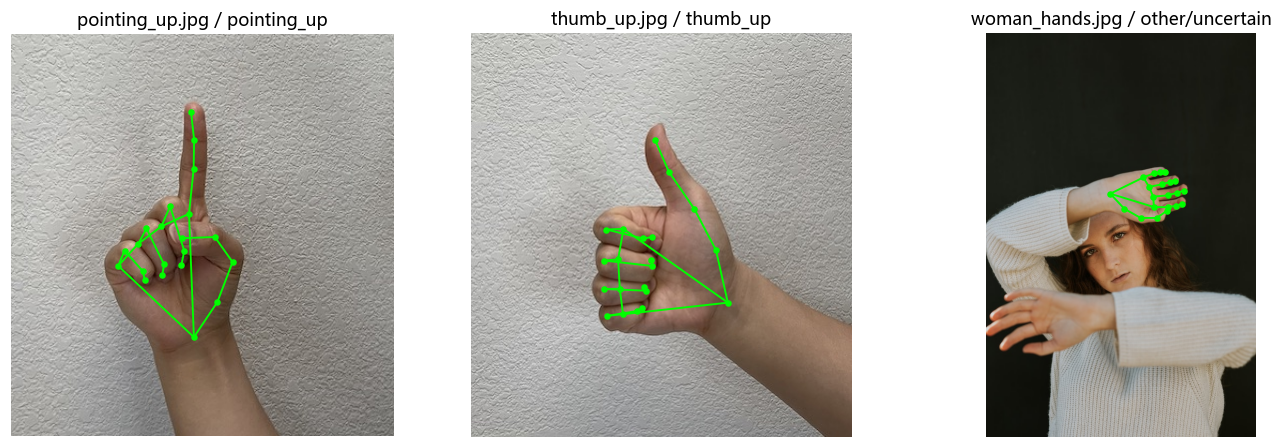

781

In [13]:
fig,axes=plt.subplots(1,3,figsize=(16,5))
gesture_rows=[]
for ax,filename in zip(axes,['pointing_up.jpg','thumb_up.jpg','woman_hands.jpg']):
    im=cv2.imread(str(DATA/filename));detected=detector.infer(im)
    r=estimator.infer(im,detected[0]) if len(detected) else None
    if r is None:
        ax.imshow(cv2.cvtColor(im,cv2.COLOR_BGR2RGB));ax.set_title('未检测到可信手');ax.axis('off');continue
    p=r[4:67].reshape(21,3)
    vector42=((p[:,:2]-p[0,:2])/(np.linalg.norm(p[9,:2]-p[0,:2])+1e-8)).reshape(-1)
    angles,extended,label=finger_state(p)
    print(filename,'特征',vector42.shape,'角度',angles.round(1),'伸直',extended.astype(int),'规则输出',label)
    draw_points(ax,im,p,HAND_EDGES,filename+' / '+label,numbers=False)
    gesture_rows.append({'image':filename,'angles':angles.tolist(),'rule_label':label,'confidence':float(r[-1])})
save_figure(PREFIX+'_gesture_rules')
(ROOT/'outputs'/(PREFIX+'_gestures.json')).write_text(json.dumps(gesture_rows,indent=2),encoding='utf-8')

## 10. 逐帧真实视频：帧→ROI→CNN→向量→坐标→业务输出

    此处顺序解码前80帧，每帧重新执行完整网络；不是把一张照片平移后伪装成新视频。逐帧JSON保留关键点数组与置信度，CSV便于检索和画曲线。为节省篇幅，图中每10帧展示一个快照。其他视频可替换路径；实时摄像头需要另外使用VideoCapture(0)并控制退出和隐私。

原视频fps 25.0 实际处理 80 可信检测 80


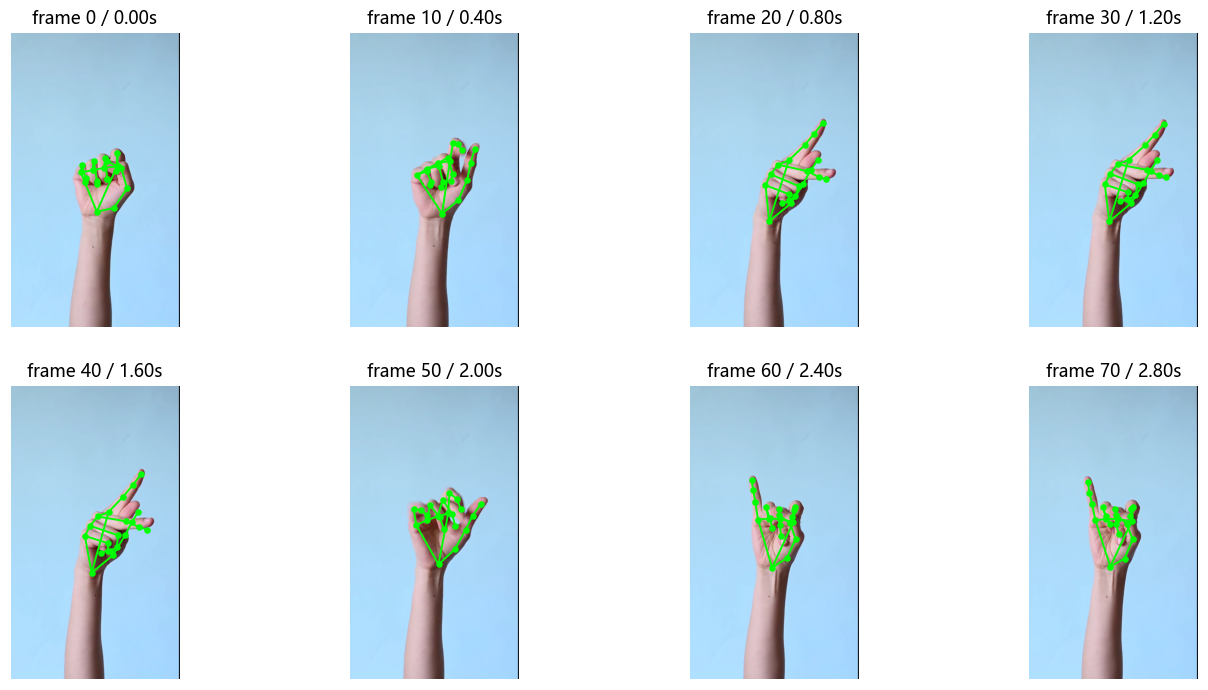

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/20_hand_video_frames.png')

In [14]:
records,snapshots,fps=infer_video(DATA/'hand_clip.mp4',detector,estimator,'hand',
    ROOT/'outputs'/(PREFIX+'_frames'),max_frames=80)
print('原视频fps',fps,'实际处理',len(records),'可信检测',sum(r['detected'] for r in records))
fig,axes=plt.subplots(2,4,figsize=(16,8))
for ax in axes.flat: ax.axis('off')
for ax,snapshot in zip(axes.flat,snapshots[:8]):
    frame,im,p,row=snapshot
    if p is not None:
        draw_points(ax,im,p,HAND_EDGES,f"frame {frame} / {row['time_s']:.2f}s",numbers=False)
    else:
        ax.imshow(cv2.cvtColor(im,cv2.COLOR_BGR2RGB));ax.set_title(f'frame {frame} 未检测');ax.axis('off')
save_figure(PREFIX+'_video_frames')

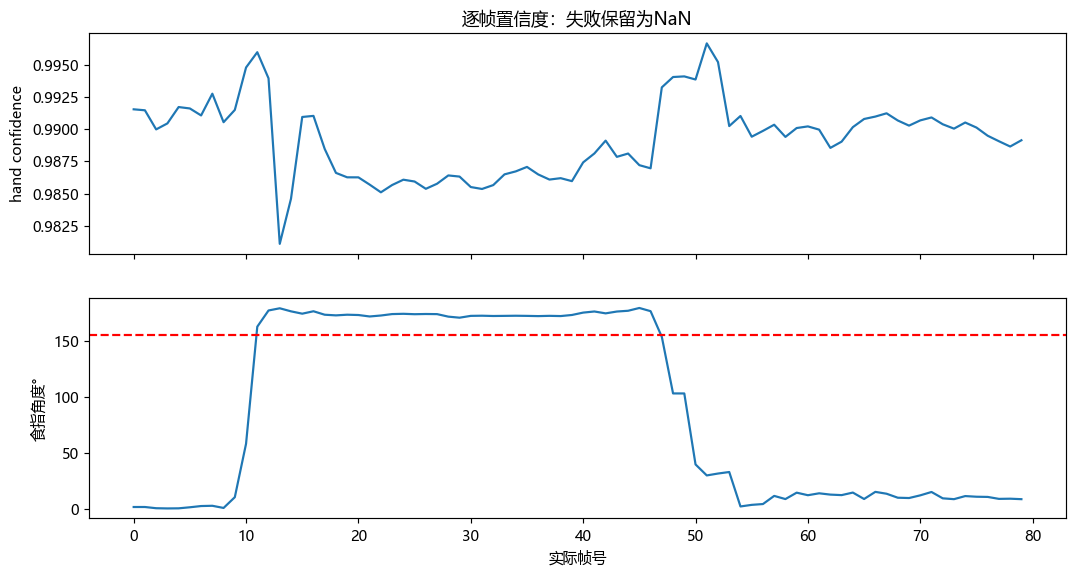

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/20_hand_timeline.png')

In [15]:
frames=[r['frame'] for r in records]
confidence=[r.get('confidence',np.nan) for r in records]
index_angles=[r.get('angles',[np.nan]*5)[1] for r in records]
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True)
axes[0].plot(frames,confidence);axes[0].set_ylabel('hand confidence');axes[0].set_title('逐帧置信度：失败保留为NaN')
axes[1].plot(frames,index_angles);axes[1].axhline(155,color='red',ls='--');axes[1].set_ylabel('食指角度°');axes[1].set_xlabel('实际帧号')
save_figure(PREFIX+'_timeline')

## 11. 自己实践与数据划分

    1. 换一张真实照片，先检查ROI，再检查关键点落点和置信度，最后解释业务输出。
    2. 在算子CSV里任选一层，用activations[index]查看全部张量；plot_channels支持start和limit，例如start=24,limit=24查看第24至47通道，再递增start即可分批查看全部通道。
    3. 修改关节角度阈值，观察错误触发；遮挡、侧视、运动模糊都应记录失败。
    4. 如果训练自己的手势或动作分类器，以“人物/录像”为组分训练、验证、测试，禁止把相邻帧随机分到不同集合。先固定划分，再只用训练集合拟合归一化统计量；视频测试标签应另行人工核对。

    本课照片只是可重复的小型推理/标注参考，**没有用这几张照片伪造训练集或独立测试成绩**。CPU/GPU速度、三维误差、动作分类准确率、完整生产稳定性没有在此验证。

    ## 来源与权利

    - OpenCV Zoo [手部模型](https://github.com/opencv/opencv_zoo/tree/48b10fa505aeb51fbd127fc60a5c660040e823b7/models/handpose_estimation_mediapipe)、[人体模型](https://github.com/opencv/opencv_zoo/tree/48b10fa505aeb51fbd127fc60a5c660040e823b7/models/pose_estimation_mediapipe)：Apache-2.0；原版包装代码和许可在reference/opencv_zoo。
    - [COCO-WholeBody](https://github.com/jin-s13/COCO-WholeBody)人工标注，小样例来自固定版本[MMPose测试资源](https://github.com/open-mmlab/mmpose/tree/759b39c13fea6ba094afc1fa932f51dc1b11cbf9/tests/data/coco)。照片权利属于原作者，具体license字段保留在JSON，项目MIT不重新授权照片。
    - [Google官方Hand Landmarker示例](https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker)及测试照片，用作清晰新图推理。
    - [TensorFlow.js手部真实测试视频](https://github.com/tensorflow/tfjs-models/blob/c731b9ebbd6f4c9e8bf99b0df76bbdbf9c25b07f/hand-pose-detection/test_data/asl_hand.25fps.mp4)、[人体下蹲视频](https://github.com/tensorflow/tfjs-models/blob/c731b9ebbd6f4c9e8bf99b0df76bbdbf9c25b07f/pose-detection/test_data/pose_squats.mp4)。原始样例和权重按需下载到data，不混入MIT学生素材许可。

    download_manifest.json记录本次下载地址和SHA256，便于复核。工程实作应复核第三方数据许可后再分发原始图像。